# **Laboratorio 3 - La tarea de clasificación**

Laura Sanchez Bernal - 202411353

Baruc Jeronimo Triana Bastidas - 202416093

**Caso: Ruta Alpes. Periodo 202620.**

Versión de trabajo: desarrollo técnico ejecutado. Las respuestas del análisis, las reflexiones sobre el uso de IA y el video quedan pendientes.

## 1. Comprensión del problema

Se busca predecir si un conductor acepta un cupón de Cafetería o de Restaurante(<20), a partir del contexto del trayecto y de su perfil. Es una tarea de clasificación supervisada binaria, ya que se cuenta con la respuesta `acepta_cupon`. Se construyen modelos separados para cada tipo de cupón.

Se toma `Sí = 1` como la clase positiva. Se utiliza F1 de esta clase para seleccionar los modelos, porque combina precisión y recall sobre la aceptación. También se reportan F1-macro y recall de la clase minoritaria para revisar si el resultado general oculta dificultades al identificar rechazos. F1-macro es el promedio del F1 de las dos clases, con el mismo peso para cada una.

## 2. Importación de las librerías

El notebook se ejecuta desde la carpeta que contiene `Data`. Las versiones utilizadas están en `requirements.txt`. En VS Code se debe seleccionar el kernel del entorno donde estén instaladas.

Si faltan dependencias, ejecutar `%pip install -r requirements.txt` en una celda y reiniciar el kernel antes de usar **Run All**. Las búsquedas de hiperparámetros pueden tardar varios minutos.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn

from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             make_scorer, classification_report,
                             ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)
sns.set_theme(style='whitegrid', palette='Set2')
RANDOM_STATE = 42
N_JOBS = 2
tipos_cupon = ['Cafetería', 'Restaurante(<20)']
target = 'acepta_cupon'
ruta_datos = Path('Data')

print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)
print('imbalanced-learn:', imblearn.__version__)

Python: 3.12.14
scikit-learn: 1.7.2
imbalanced-learn: 0.14.0


## 3. Carga de los datos y revisión inicial

Se utilizan únicamente los archivos de `202620/Laboratorios/L3/Data`. El archivo etiquetado se usa para construir y evaluar los modelos. `Lab3_datos_Prueba.xlsx` contiene registros sin respuesta y se reserva para generar las predicciones al final.

In [2]:
datos_originales = pd.read_excel(ruta_datos / 'Lab3_Datos.xlsx')
diccionario = pd.read_excel(ruta_datos / 'Lab3_diccionario_Datos.xlsx')
print('Dimensión original:', datos_originales.shape)
display(datos_originales.head())
display(diccionario[['Variable', 'Tipo']])

Dimensión original: (12664, 26)


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


,Variable,Tipo
0,destino,Categórica nominal
1,acompanante,Categórica nominal
2,clima,Categórica nominal
3,temperatura,Numérica entero
4,hora,Categórica ordinal
5,cupon,Categórica nominal
6,vigencia_cupon,Categórica nominal
7,genero,Categórica nominal
8,edad,Categórica ordinal
9,estado_civil,Categórica nominal


### Selección de los dos tipos de cupón y unicidad

Se filtran los dos tipos solicitados. Antes de separar entrenamiento y test se retiran las filas completamente repetidas, conservando una copia. Esto evita que una misma fila aparezca en ambos conjuntos. Al no contar con un identificador del conductor, esta decisión supone que las repeticiones exactas son duplicados del registro.

No se eliminan perfiles que tienen las mismas características y respuestas distintas: pueden representar personas diferentes y no hay información para determinar cuál respuesta sería incorrecta.

In [3]:
data = datos_originales.loc[datos_originales['cupon'].isin(tipos_cupon)].copy()
# Se retiran espacios de los extremos, sin cambiar el significado de las categorías.
for columna in data.select_dtypes(include='object').columns:
    data[columna] = data[columna].str.strip()

resumen_inicial = []
for tipo in tipos_cupon:
    subconjunto = data.loc[data['cupon'] == tipo]
    resumen_inicial.append({
        'Cupón': tipo,
        'Filas originales': len(subconjunto),
        'Duplicados exactos': int(subconjunto.duplicated().sum()),
        'Sin etiqueta': int(subconjunto[target].isna().sum()),
        'Acepta (%)': 100 * subconjunto[target].eq('Sí').mean()
    })
display(pd.DataFrame(resumen_inicial).round(2))
assert data[target].isin(['Sí', 'No']).all(), 'Revisar las etiquetas antes de continuar.'
data = data.drop_duplicates().copy()
print('Filas después de retirar duplicados:', len(data))

,Cupón,Filas originales,Duplicados exactos,Sin etiqueta,Acepta (%)
0,Cafetería,3986,7,0,49.90
1,Restaurante(<20),2776,7,0,70.68


Filas después de retirar duplicados: 6748


## 4. Separación de entrenamiento y test

Se conserva el 25 % para test y `random_state=42`, como en el Laboratorio 2. Se añade `stratify=y` para mantener la proporción de las clases. La exploración detallada y las decisiones de preparación se realizan sobre entrenamiento. Test se utiliza después de seleccionar las configuraciones mediante validación cruzada.

La partición se hace por registros. Sin un identificador de conductor no es posible asegurar que todos los escenarios de una misma persona queden en una sola partición.

In [4]:
particiones = {}
resumen_particiones = []
for tipo in tipos_cupon:
    subconjunto = data.loc[data['cupon'] == tipo].copy()
    X = subconjunto.drop(columns=target)
    y = subconjunto[target].map({'No': 0, 'Sí': 1}).astype(int)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
    )
    particiones[tipo] = {'X_train': X_train, 'X_test': X_test,
                         'y_train': y_train, 'y_test': y_test}
    resumen_particiones.append({
        'Cupón': tipo, 'Entrenamiento': len(X_train), 'Test': len(X_test),
        'No en entrenamiento': int(y_train.eq(0).sum()),
        'Sí en entrenamiento': int(y_train.eq(1).sum())
    })
display(pd.DataFrame(resumen_particiones))

,Cupón,Entrenamiento,Test,No en entrenamiento,Sí en entrenamiento
0,Cafetería,2984,995,1497,1487
1,Restaurante(<20),2076,693,607,1469


## 5. Exploración de los datos de entrenamiento

### 5.1. Distribución de la variable objetivo

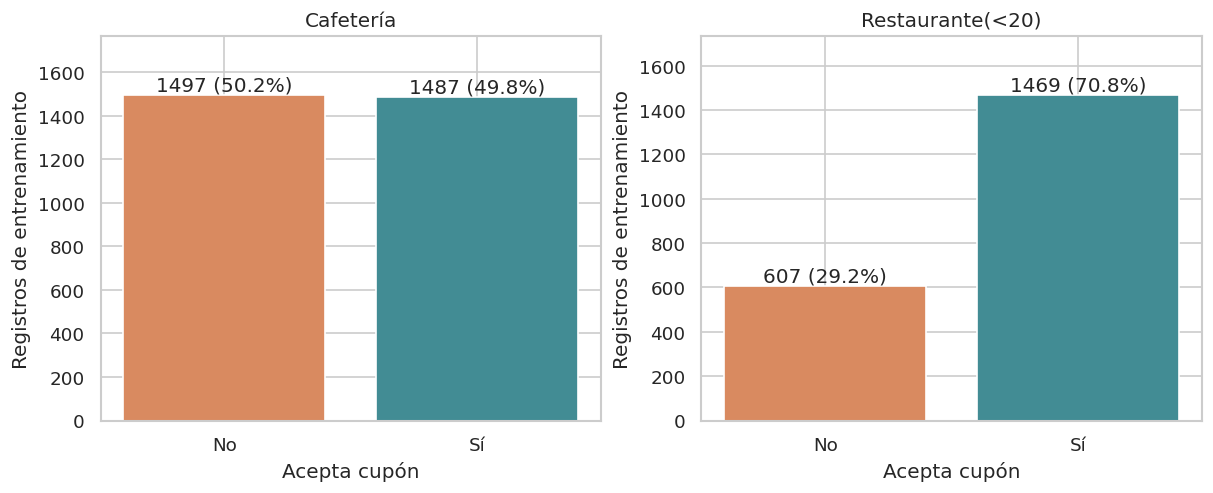

,Cupón,Clase,Cantidad,Porcentaje
0,Cafetería,No,1497,50.17
1,Cafetería,Sí,1487,49.83
2,Restaurante(<20),No,607,29.24
3,Restaurante(<20),Sí,1469,70.76


In [5]:
distribucion_clases = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, tipo in zip(axes, tipos_cupon):
    y_train = particiones[tipo]['y_train']
    conteos = y_train.value_counts().reindex([0, 1], fill_value=0)
    ax.bar(['No', 'Sí'], conteos.values, color=['#d98a60', '#428c94'])
    ax.set(title=tipo, xlabel='Acepta cupón', ylabel='Registros de entrenamiento')
    for i, valor in enumerate(conteos):
        ax.text(i, valor, f'{valor} ({valor / len(y_train):.1%})', ha='center', va='bottom')
    ax.set_ylim(0, conteos.max() * 1.18)
    for clase, cantidad in conteos.items():
        distribucion_clases.append({'Cupón': tipo, 'Clase': {0: 'No', 1: 'Sí'}[clase],
                                    'Cantidad': cantidad, 'Porcentaje': 100*cantidad/len(y_train)})
plt.show()
display(pd.DataFrame(distribucion_clases).round(2))

Cafetería presenta proporciones cercanas entre aceptación y rechazo. En Restaurante(<20), la aceptación es mayoritaria y la clase minoritaria es **No**. Por eso el balanceo se evalúa específicamente para Restaurante(<20), revisando el recall de los rechazos.

### 5.2. Completitud y variedad de valores

In [6]:
resumen_calidad = []
for tipo in tipos_cupon:
    X_train = particiones[tipo]['X_train']
    tabla = pd.DataFrame({
        'Cupón': tipo, 'Variable': X_train.columns,
        'Tipo leído': X_train.dtypes.astype(str).values,
        'Faltantes': X_train.isna().sum().values,
        'Faltantes (%)': 100 * X_train.isna().mean().values,
        'Valores distintos': X_train.nunique().values
    })
    resumen_calidad.append(tabla)
resumen_calidad = pd.concat(resumen_calidad, ignore_index=True)
display(resumen_calidad.loc[
    (resumen_calidad['Faltantes'] > 0) | (resumen_calidad['Valores distintos'] <= 1)
].round(2))

for tipo in tipos_cupon:
    print('\n', tipo)
    display(particiones[tipo]['X_train'].describe(include='object').T[['count', 'unique', 'top', 'freq']])

,Cupón,Variable,Tipo leído,Faltantes,Faltantes (%),Valores distintos
5,Cafetería,cupon,object,0,0.00,1
14,Cafetería,vehiculo,object,2959,99.16,5
15,Cafetería,frecuencia_bar,object,29,0.97,5
16,Cafetería,frecuencia_cafeteria,object,56,1.88,5
17,Cafetería,frecuencia_comida_para_llevar,object,38,1.27,5
18,Cafetería,frecuencia_restaurante_menos_20,object,39,1.31,5
19,Cafetería,frecuencia_restaurante_20_a_50,object,39,1.31,5
20,Cafetería,tiempo_cupon_mayor_5min,object,0,0.00,1
30,Restaurante(<20),cupon,object,0,0.00,1
39,Restaurante(<20),vehiculo,object,2056,99.04,5



 Cafetería


,count,unique,top,freq
destino,2984,3,Sin lugar urgente,1610
acompanante,2984,4,Solo,1674
clima,2984,3,Soleado,2585
hora,2984,5,6:00 p.m.,830
cupon,2984,1,Cafetería,2984
vigencia_cupon,2984,2,2 horas,1678
genero,2984,2,Femenino,1539
edad,2984,8,21,663
estado_civil,2984,5,Soltero(a),1153
tiene_hijos,2984,2,No,1830



 Restaurante(<20)


,count,unique,top,freq
destino,2076,3,Sin lugar urgente,1292
acompanante,2076,4,Solo,1059
clima,2076,3,Soleado,1680
hora,2076,5,6:00 p.m.,555
cupon,2076,1,Restaurante(<20),2076
vigencia_cupon,2076,2,2 horas,1072
genero,2076,2,Femenino,1047
edad,2076,8,21,447
estado_civil,2076,5,Casado(a),823
tiene_hijos,2076,2,No,1228


`vehiculo` tiene más del 99 % de valores faltantes, por lo que imputarlo significaría completar casi toda la columna. En las variables de frecuencia de consumo los faltantes son pocos y se pueden imputar con la moda. `cupon` y `tiempo_cupon_mayor_5min` son constantes dentro de cada subconjunto.

### 5.3. Validez y consistencia

Se contrastan los valores con el diccionario. La temperatura está en Fahrenheit y solo puede tomar 30, 55 u 80; no se trata de una medición continua con valores extremos que deban recortarse. También se revisa la coherencia de las distancias y de las dos variables de dirección.

In [7]:
dominios = {
    'destino': ['Casa', 'Sin lugar urgente', 'Trabajo'],
    'acompanante': ['Solo', 'Amigo(s)', 'Hijo(s)', 'Pareja'],
    'clima': ['Soleado', 'Lluvioso', 'Nevado'],
    'temperatura': [30, 55, 80],
    'hora': ['7:00 a.m.', '10:00 a.m.', '2:00 p.m.', '6:00 p.m.', '10:00 p.m.'],
    'vigencia_cupon': ['2 horas', '1 día'],
    'genero': ['Femenino', 'Masculino'],
    'edad': ['menor de 21', '21', '26', '31', '36', '41', '46', '50 o más'],
    'estado_civil': ['Soltero(a)', 'Casado(a)', 'Unión libre', 'Divorciado(a)', 'Viudo(a)'],
    'educacion': ['Bachillerato incompleto', 'Bachillerato completo',
                  'Estudios universitarios sin título', 'Técnico/Tecnólogo',
                  'Pregrado', 'Posgrado (Maestría o Doctorado)'],
    'ingreso': ['Menos de $12.500', '$12.500 - $24.999', '$25.000 - $37.499',
                '$37.500 - $49.999', '$50.000 - $62.499', '$62.500 - $74.999',
                '$75.000 - $87.499', '$87.500 - $99.999', '$100.000 o más']
}
for columna in ['tiene_hijos', 'tiempo_cupon_mayor_5min', 'tiempo_cupon_mayor_15min',
                'tiempo_cupon_mayor_25min', 'misma_direccion', 'direccion_opuesta']:
    dominios[columna] = ['Sí', 'No']
for columna in data.columns[data.columns.str.startswith('frecuencia_')]:
    dominios[columna] = ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8']

revision = []
for tipo in tipos_cupon:
    X_train = particiones[tipo]['X_train']
    invalidos = {c: int((X_train[c].notna() & ~X_train[c].isin(valores)).sum())
                 for c, valores in dominios.items()}
    revision.append({
        'Cupón': tipo,
        'Valores fuera de dominios revisados': sum(invalidos.values()),
        'Distancia >25 min sin >15 min': int(((X_train['tiempo_cupon_mayor_25min'] == 'Sí') &
                                             (X_train['tiempo_cupon_mayor_15min'] == 'No')).sum()),
        'Direcciones no complementarias': int((X_train['misma_direccion'] ==
                                                X_train['direccion_opuesta']).sum())
    })
    print(tipo, '- inconsistencias por variable:', {c:n for c,n in invalidos.items() if n})
display(pd.DataFrame(revision))

Cafetería - inconsistencias por variable: {}
Restaurante(<20) - inconsistencias por variable: {}


,Cupón,Valores fuera de dominios revisados,Distancia >25 min sin >15 min,Direcciones no complementarias
0,Cafetería,0,0,0
1,Restaurante(<20),0,0,0


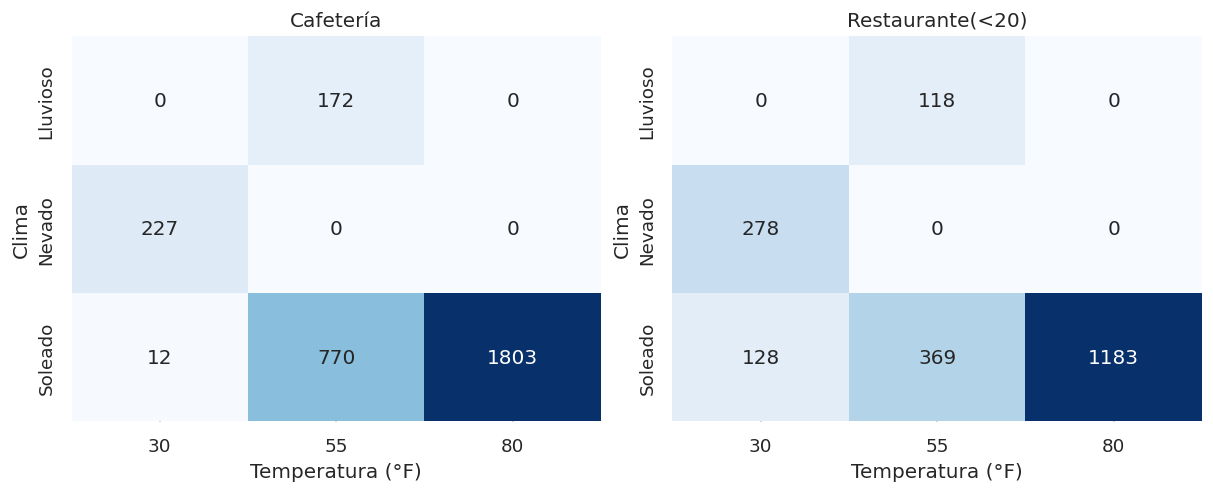

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, tipo in zip(axes, tipos_cupon):
    X_train = particiones[tipo]['X_train']
    tabla = pd.crosstab(X_train['clima'], X_train['temperatura'])
    sns.heatmap(tabla, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set(title=tipo, xlabel='Temperatura (°F)', ylabel='Clima')
plt.show()

No se encontraron valores fuera de los dominios revisados ni inconsistencias en distancia. `misma_direccion` y `direccion_opuesta` expresan información complementaria, por lo que se conserva solo la primera. Clima y temperatura están relacionadas, pero no son equivalentes en todos los casos; se conservan ambas. `ocupacion` se revisó mediante sus categorías observadas, ya que el diccionario solo enumera ejemplos de sus 25 categorías.

### 5.4. Aceptación según contexto y hábitos

Se comparan las proporciones observadas en entrenamiento y el número de registros de cada categoría. Estas relaciones son descriptivas y no prueban que una variable cause la aceptación. Las gráficas de frecuencia muestran las categorías conocidas; los faltantes se conservan para imputarlos después.

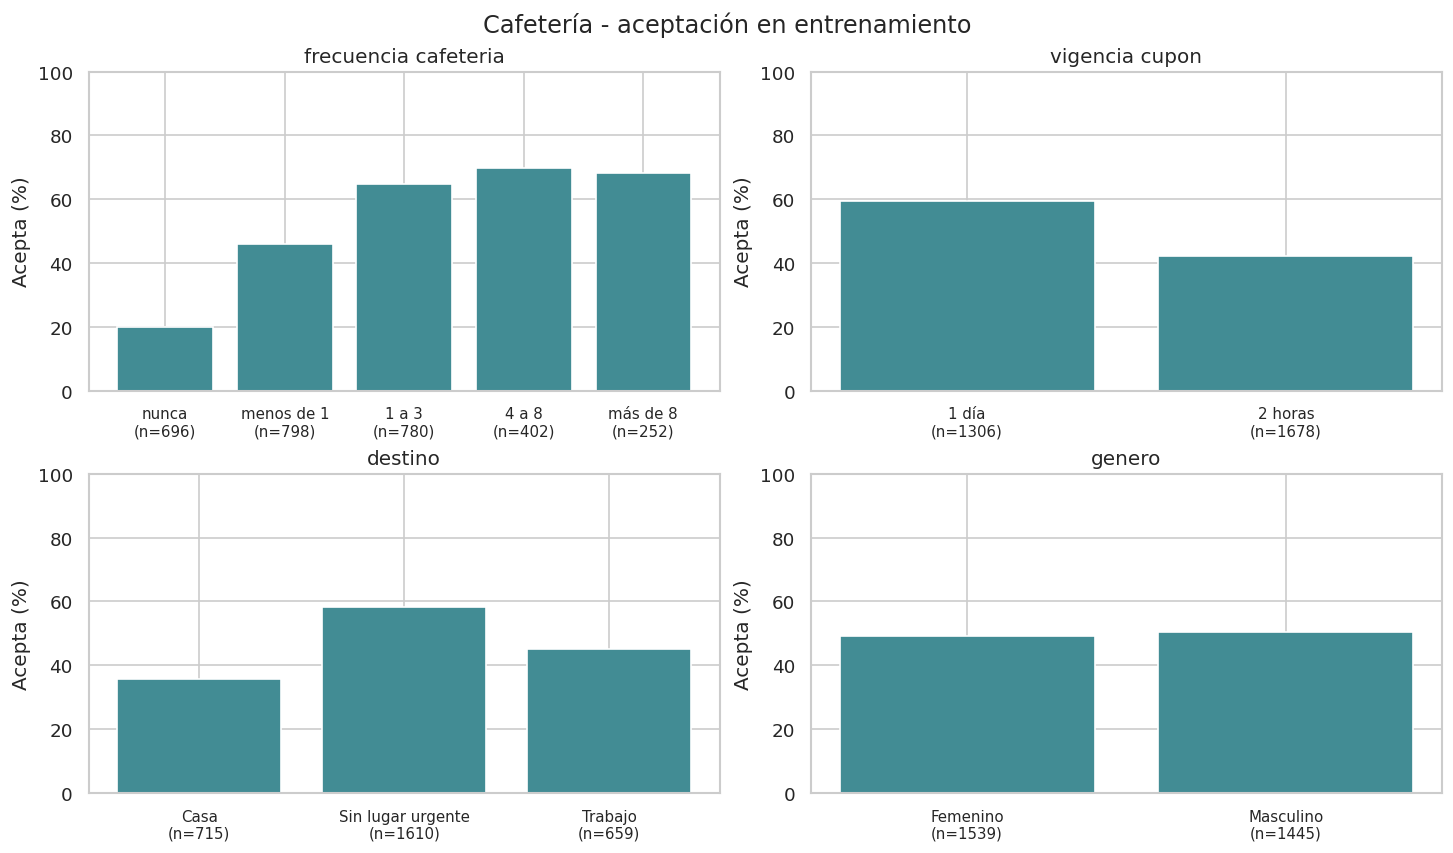

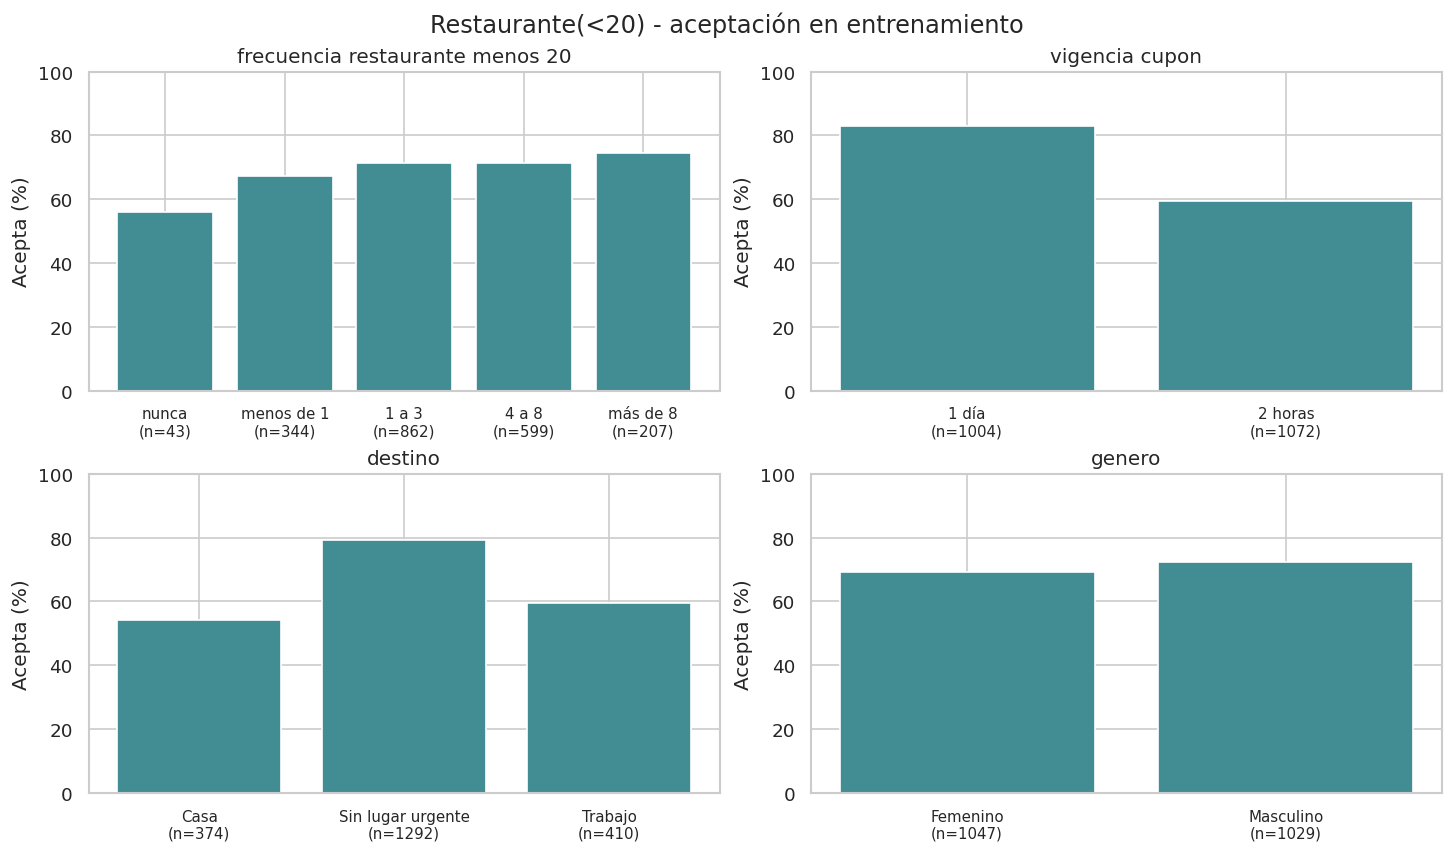

In [9]:
variables_exploracion = {
    'Cafetería': ['frecuencia_cafeteria', 'vigencia_cupon', 'destino', 'genero'],
    'Restaurante(<20)': ['frecuencia_restaurante_menos_20', 'vigencia_cupon', 'destino', 'genero']
}
for tipo in tipos_cupon:
    exploracion = particiones[tipo]['X_train'].copy()
    exploracion['acepta'] = particiones[tipo]['y_train']
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
    fig.suptitle(f'{tipo} - aceptación en entrenamiento')
    for ax, columna in zip(axes.flat, variables_exploracion[tipo]):
        tabla = exploracion.groupby(columna, dropna=False)['acepta'].agg(['size', 'mean'])
        if columna.startswith('frecuencia_'):
            tabla = tabla.reindex(['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8'])
        etiquetas = [f'{categoria}\n(n={int(n)})' for categoria, n in zip(tabla.index, tabla['size'])]
        ax.bar(etiquetas, 100*tabla['mean'], color='#428c94')
        ax.set(title=columna.replace('_', ' '), ylabel='Acepta (%)', ylim=(0, 100))
        ax.tick_params(axis='x', labelsize=9)
    plt.show()

## 6. Propuesta de limpieza y preparación

| Decisión | Justificación |
|---|---|
| Retirar duplicados exactos | Evitar repetir la misma observación en entrenamiento y test. |
| Excluir `vehiculo` | Tiene más del 99 % de datos faltantes. |
| Excluir `cupon` y `tiempo_cupon_mayor_5min` | Son constantes dentro de cada problema. |
| Excluir `direccion_opuesta` | Es el complemento de `misma_direccion`. |
| Imputar categorías con la moda | Los faltantes restantes son pocos y la moda conserva una categoría válida. |
| Codificar con One-Hot Encoding | Permite usar categorías sin asignar distancias numéricas arbitrarias. |
| Estandarizar temperatura | Hace comparable su escala para la regularización y las distancias de SMOTE. |

Aunque edad, ingreso y frecuencias tienen un orden, sus categorías no representan necesariamente distancias iguales. Se utiliza One-Hot Encoding también para ellas. Se conservan todas las categorías, lo que evita privilegiar una categoría de referencia al calcular distancias para SMOTE. La regresión logística siempre se entrena con regularización.

Las transformaciones se ajustan dentro de cada fold. Los árboles no requieren estandarización, pero se conserva la misma preparación para comparar los modelos y su versión con SMOTE. No se agregan características ni modelos ajenos a lo solicitado.

In [10]:
columnas_excluir = ['cupon', 'vehiculo', 'tiempo_cupon_mayor_5min', 'direccion_opuesta']
numeric_features = ['temperatura']
categorical_features = [c for c in data.columns
                        if c not in columnas_excluir + numeric_features + [target]]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
], remainder='drop')

print('Variables numéricas:', numeric_features)
print('Variables categóricas:', categorical_features)
print('Variables excluidas:', columnas_excluir)

Variables numéricas: ['temperatura']
Variables categóricas: ['destino', 'acompanante', 'clima', 'hora', 'vigencia_cupon', 'genero', 'edad', 'estado_civil', 'tiene_hijos', 'educacion', 'ocupacion', 'ingreso', 'frecuencia_bar', 'frecuencia_cafeteria', 'frecuencia_comida_para_llevar', 'frecuencia_restaurante_menos_20', 'frecuencia_restaurante_20_a_50', 'tiempo_cupon_mayor_15min', 'tiempo_cupon_mayor_25min', 'misma_direccion']
Variables excluidas: ['cupon', 'vehiculo', 'tiempo_cupon_mayor_5min', 'direccion_opuesta']


## 7. Validación cruzada y criterio de comparación

Se utilizan cinco folds estratificados con la misma semilla para todos los modelos. `GridSearchCV` selecciona por F1 de la clase Sí y también calcula F1-macro y recall de No. Se guardan el promedio y la desviación estándar entre folds. Los hiperparámetros se eligen usando solo entrenamiento; no se ajusta el umbral de 0.5 con test.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas_cv = {
    'f1': make_scorer(f1_score, pos_label=1, zero_division=0),
    'f1_macro': make_scorer(f1_score, average='macro', zero_division=0),
    'recall_no': make_scorer(recall_score, pos_label=0, zero_division=0)
}
busquedas = {}

def ejecutar_busqueda(tipo, nombre, pipeline, parametros):
    p = particiones[tipo]
    grid = GridSearchCV(
        estimator=pipeline, param_grid=parametros, cv=cv,
        scoring=metricas_cv, refit='f1', n_jobs=N_JOBS,
        return_train_score=True, error_score='raise'
    )
    grid.fit(p['X_train'], p['y_train'])
    busquedas[(tipo, nombre)] = grid
    i = grid.best_index_
    print(f'{tipo} - {nombre}')
    print('Mejores hiperparámetros:', grid.best_params_)
    print(f"F1 (Sí) en CV: {grid.best_score_:.4f} ± {grid.cv_results_['std_test_f1'][i]:.4f}")
    print(f"F1-macro en CV: {grid.cv_results_['mean_test_f1_macro'][i]:.4f}")
    display(pd.DataFrame(grid.cv_results_).sort_values('rank_test_f1')[
        ['params', 'mean_train_f1', 'mean_test_f1', 'std_test_f1',
         'mean_test_f1_macro', 'mean_test_recall_no']
    ].head(5).round(4))
    return grid

## 8. Modelos de regresión logística

Se exploran L1 y L2, distintos valores de `C` y los solvers `liblinear` y `lbfgs`. Un `C` menor implica mayor regularización. Se separan las combinaciones porque `lbfgs` no admite L1. Se aumenta `max_iter` para permitir la convergencia, sin ocultar advertencias.

In [12]:
param_grid_logistica = [
    {'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear'],
     'modelo__C': [0.1, 1, 10]},
    {'modelo__penalty': ['l2'], 'modelo__solver': ['liblinear', 'lbfgs'],
     'modelo__C': [0.1, 1, 10]}
]
pipeline_logistica = Pipeline(steps=[
    ('preprocesamiento', clone(preprocessor)),
    ('modelo', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE, n_jobs=1))
])

In [13]:
grid_logistica_cafeteria = ejecutar_busqueda(
    'Cafetería', 'Regresión logística', clone(pipeline_logistica), param_grid_logistica
)

Cafetería - Regresión logística
Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}
F1 (Sí) en CV: 0.7188 ± 0.0113
F1-macro en CV: 0.7175


,params,mean_train_f1,mean_test_f1,std_test_f1,mean_test_f1_macro,mean_test_recall_no
3,"{'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}",0.7352,0.7188,0.0113,0.7175,0.7107
4,"{'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'lbfgs'}",0.7356,0.7188,0.0113,0.7175,0.7107
0,"{'modelo__C': 0.1, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}",0.7262,0.7184,0.0169,0.7141,0.6967
6,"{'modelo__C': 1, 'modelo__penalty': 'l2', 'modelo__solver': 'lbfgs'}",0.7390,0.7162,0.0179,0.7154,0.7101
1,"{'modelo__C': 1, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}",0.7390,0.7158,0.0166,0.7144,0.7074


In [14]:
grid_logistica_restaurante = ejecutar_busqueda(
    'Restaurante(<20)', 'Regresión logística', clone(pipeline_logistica), param_grid_logistica
)

Restaurante(<20) - Regresión logística
Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}
F1 (Sí) en CV: 0.8446 ± 0.0079
F1-macro en CV: 0.6571


,params,mean_train_f1,mean_test_f1,std_test_f1,mean_test_f1_macro,mean_test_recall_no
0,"{'modelo__C': 0.1, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}",0.8491,0.8446,0.0079,0.6571,0.3641
3,"{'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}",0.8544,0.8442,0.0079,0.6634,0.3823
4,"{'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'lbfgs'}",0.8546,0.8440,0.0082,0.6624,0.3806
1,"{'modelo__C': 1, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}",0.8555,0.8428,0.0103,0.6679,0.4004
6,"{'modelo__C': 1, 'modelo__penalty': 'l2', 'modelo__solver': 'lbfgs'}",0.8550,0.8397,0.0111,0.6651,0.4020


## 9. Modelos de árboles de decisión

Se exploran `max_depth`, `min_samples_leaf` y `criterion`. Limitar la profundidad y exigir más muestras por hoja permite controlar el sobreajuste. También se incluye un árbol sin límite de profundidad para contrastar su comportamiento. Se comparan Gini y entropía.

In [15]:
param_grid_arbol = {
    'modelo__max_depth': [3, 5, 10, None],
    'modelo__min_samples_leaf': [1, 5, 15],
    'modelo__criterion': ['gini', 'entropy']
}
pipeline_arbol = Pipeline(steps=[
    ('preprocesamiento', clone(preprocessor)),
    ('modelo', DecisionTreeClassifier(random_state=RANDOM_STATE))
])

In [16]:
grid_arbol_cafeteria = ejecutar_busqueda(
    'Cafetería', 'Árbol de decisión', clone(pipeline_arbol), param_grid_arbol
)

Cafetería - Árbol de decisión
Mejores hiperparámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 1}
F1 (Sí) en CV: 0.7083 ± 0.0254
F1-macro en CV: 0.7091


,params,mean_train_f1,mean_test_f1,std_test_f1,mean_test_f1_macro,mean_test_recall_no
18,"{'modelo__criterion': 'entropy', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 1}",0.8567,0.7083,0.0254,0.7091,0.7101
6,"{'modelo__criterion': 'gini', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 1}",0.8731,0.7078,0.0105,0.7052,0.6954
8,"{'modelo__criterion': 'gini', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 15}",0.7711,0.6948,0.0277,0.6922,0.6807
21,"{'modelo__criterion': 'entropy', 'modelo__max_depth': None, 'modelo__min_samples_leaf'...",0.9992,0.6944,0.0168,0.6942,0.6914
19,"{'modelo__criterion': 'entropy', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 5}",0.8187,0.6928,0.0200,0.6948,0.6987


In [17]:
grid_arbol_restaurante = ejecutar_busqueda(
    'Restaurante(<20)', 'Árbol de decisión', clone(pipeline_arbol), param_grid_arbol
)

Restaurante(<20) - Árbol de decisión
Mejores hiperparámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 5}
F1 (Sí) en CV: 0.8375 ± 0.0110
F1-macro en CV: 0.6122


,params,mean_train_f1,mean_test_f1,std_test_f1,mean_test_f1_macro,mean_test_recall_no
13,"{'modelo__criterion': 'entropy', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 5}",0.8451,0.8375,0.0110,0.6122,0.2832
12,"{'modelo__criterion': 'entropy', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 1}",0.8456,0.8371,0.0109,0.6091,0.2782
14,"{'modelo__criterion': 'entropy', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 15}",0.8459,0.8361,0.0095,0.6019,0.2651
16,"{'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5}",0.8537,0.8358,0.0096,0.6536,0.3823
1,"{'modelo__criterion': 'gini', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 5}",0.8461,0.8355,0.0138,0.6037,0.2668


## 10. Modelos de Random Forest

Se combinan árboles entrenados sobre muestras y subconjuntos de variables diferentes. Se exploran el número de árboles, su profundidad y el mínimo de muestras por hoja. Los rangos permiten comparar bosques con distinta complejidad manteniendo un tiempo de ejecución razonable. Se utiliza `n_jobs=1` en cada bosque porque la paralelización ya se realiza en `GridSearchCV`.

In [18]:
param_grid_rf = {
    'modelo__n_estimators': [100, 200],
    'modelo__max_depth': [6, 12, None],
    'modelo__min_samples_leaf': [1, 3, 5]
}
pipeline_rf = Pipeline(steps=[
    ('preprocesamiento', clone(preprocessor)),
    ('modelo', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))
])

In [19]:
grid_rf_cafeteria = ejecutar_busqueda(
    'Cafetería', 'Random Forest', clone(pipeline_rf), param_grid_rf
)

Cafetería - Random Forest
Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1 (Sí) en CV: 0.7605 ± 0.0146
F1-macro en CV: 0.7597


,params,mean_train_f1,mean_test_f1,std_test_f1,mean_test_f1_macro,mean_test_recall_no
13,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}",0.9992,0.7605,0.0146,0.7597,0.7541
12,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}",0.9992,0.7579,0.0148,0.7590,0.7615
7,"{'modelo__max_depth': 12, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}",0.9659,0.7535,0.0111,0.7506,0.7368
6,"{'modelo__max_depth': 12, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}",0.9647,0.7494,0.0072,0.7490,0.7448
14,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 100}",0.9067,0.7435,0.0102,0.7409,0.7288


In [20]:
grid_rf_restaurante = ejecutar_busqueda(
    'Restaurante(<20)', 'Random Forest', clone(pipeline_rf), param_grid_rf
)

Restaurante(<20) - Random Forest
Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1 (Sí) en CV: 0.8510 ± 0.0118
F1-macro en CV: 0.6853


,params,mean_train_f1,mean_test_f1,std_test_f1,mean_test_f1_macro,mean_test_recall_no
13,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}",0.9995,0.8510,0.0118,0.6853,0.4218
12,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}",0.9995,0.8502,0.0107,0.6844,0.4218
6,"{'modelo__max_depth': 12, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}",0.9546,0.8469,0.0072,0.6607,0.3674
15,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 200}",0.9042,0.8469,0.0113,0.6586,0.3625
9,"{'modelo__max_depth': 12, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 200}",0.8944,0.8462,0.0118,0.6529,0.3492


## 11. Balanceo de Restaurante(<20) con SMOTE

Se toma el algoritmo con mayor F1 en validación cruzada para Restaurante(<20) y se repite su búsqueda con SMOTE, usando la misma partición, folds y rango de hiperparámetros. Así se comparan versiones optimizadas con y sin balanceo del mismo algoritmo.

SMOTE se coloca dentro del pipeline de `imbalanced-learn`, después de preparar las variables y antes del modelo. Solo genera ejemplos en la parte de entrenamiento de cada fold. La validación y test conservan sus proporciones originales.

Se aplica el SMOTE visto en la práctica P9 sobre la representación numérica. Al interpolar columnas one-hot puede producir valores fraccionarios que no representan categorías reales; esta es una limitación del experimento con estos datos. Los ejemplos sintéticos no se interpretan como perfiles de conductores ni se incluyen en test.

In [21]:
nombre_base_restaurante = max(
    [nombre for tipo, nombre in busquedas if tipo == 'Restaurante(<20)'],
    key=lambda nombre: busquedas[('Restaurante(<20)', nombre)].best_score_
)
grid_base_restaurante = busquedas[('Restaurante(<20)', nombre_base_restaurante)]
parametros_por_modelo = {
    'Regresión logística': param_grid_logistica,
    'Árbol de decisión': param_grid_arbol,
    'Random Forest': param_grid_rf
}
pipeline_smote = ImbPipeline(steps=[
    ('preprocesamiento', clone(preprocessor)),
    ('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
    ('modelo', clone(grid_base_restaurante.best_estimator_.named_steps['modelo']))
])
nombre_smote = nombre_base_restaurante + ' + SMOTE'
print('Algoritmo elegido por CV para el experimento:', nombre_base_restaurante)
grid_smote = ejecutar_busqueda(
    'Restaurante(<20)', nombre_smote, pipeline_smote,
    parametros_por_modelo[nombre_base_restaurante]
)

Algoritmo elegido por CV para el experimento: Random Forest
Restaurante(<20) - Random Forest + SMOTE
Mejores hiperparámetros: {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1 (Sí) en CV: 0.8541 ± 0.0135
F1-macro en CV: 0.7047


,params,mean_train_f1,mean_test_f1,std_test_f1,mean_test_f1_macro,mean_test_recall_no
7,"{'modelo__max_depth': 12, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}",0.9785,0.8541,0.0135,0.7047,0.4713
6,"{'modelo__max_depth': 12, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}",0.9781,0.8525,0.0099,0.7029,0.4730
12,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}",0.9995,0.8518,0.0104,0.7064,0.4844
13,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}",0.9995,0.8503,0.0080,0.6988,0.4663
8,"{'modelo__max_depth': 12, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 100}",0.9212,0.8486,0.0088,0.6980,0.4713


In [22]:
# Revisión del balanceo únicamente sobre entrenamiento.
p = particiones['Restaurante(<20)']
preparador_revision = clone(preprocessor)
X_train_transformado = preparador_revision.fit_transform(p['X_train'], p['y_train'])
_, y_train_balanceado = SMOTE(random_state=RANDOM_STATE, k_neighbors=5).fit_resample(
    X_train_transformado, p['y_train']
)
conteos_balanceo = pd.DataFrame({
    'Sin SMOTE': p['y_train'].value_counts().reindex([0, 1]),
    'Con SMOTE': pd.Series(y_train_balanceado).value_counts().reindex([0, 1])
}).rename(index={0: 'No', 1: 'Sí'})
display(conteos_balanceo)

,Sin SMOTE,Con SMOTE
acepta_cupon,,
No,607,1469
Sí,1469,1469


## 12. Comparación y selección por validación cruzada

La selección se hace antes de consultar test. Para cada cupón se conserva el pipeline con mayor F1 promedio de la clase Sí en validación cruzada. La tabla incluye F1-macro, recall de No y variabilidad para que la selección pueda revisarse junto con el comportamiento de ambas clases. En Restaurante(<20) también participa la alternativa con SMOTE.

In [23]:
filas_cv = []
for (tipo, nombre), grid in busquedas.items():
    i = grid.best_index_
    filas_cv.append({
        'Cupón': tipo, 'Modelo': nombre,
        'F1 train folds': grid.cv_results_['mean_train_f1'][i],
        'F1 CV (Sí)': grid.best_score_,
        'Desv. F1 CV': grid.cv_results_['std_test_f1'][i],
        'F1-macro CV': grid.cv_results_['mean_test_f1_macro'][i],
        'Recall No CV': grid.cv_results_['mean_test_recall_no'][i]
    })
tabla_cv = pd.DataFrame(filas_cv)
display(tabla_cv.round(4))

seleccionados = {}
for tipo in tipos_cupon:
    fila = tabla_cv.loc[tabla_cv['Cupón'] == tipo].sort_values('F1 CV (Sí)', ascending=False).iloc[0]
    seleccionados[tipo] = fila['Modelo']
    print(f"{tipo}: {fila['Modelo']}; F1 CV = {fila['F1 CV (Sí)']:.4f}, "
          f"desviación = {fila['Desv. F1 CV']:.4f}.")

,Cupón,Modelo,F1 train folds,F1 CV (Sí),Desv. F1 CV,F1-macro CV,Recall No CV
0,Cafetería,Regresión logística,0.7352,0.7188,0.0113,0.7175,0.7107
1,Restaurante(<20),Regresión logística,0.8491,0.8446,0.0079,0.6571,0.3641
2,Cafetería,Árbol de decisión,0.8567,0.7083,0.0254,0.7091,0.7101
3,Restaurante(<20),Árbol de decisión,0.8451,0.8375,0.0110,0.6122,0.2832
4,Cafetería,Random Forest,0.9992,0.7605,0.0146,0.7597,0.7541
5,Restaurante(<20),Random Forest,0.9995,0.8510,0.0118,0.6853,0.4218
6,Restaurante(<20),Random Forest + SMOTE,0.9785,0.8541,0.0135,0.7047,0.4713


Cafetería: Random Forest; F1 CV = 0.7605, desviación = 0.0146.
Restaurante(<20): Random Forest + SMOTE; F1 CV = 0.8541, desviación = 0.0135.


## 13. Evaluación sobre test

Se evalúan los modelos elegidos por cada búsqueda sobre el mismo test de su tipo de cupón. Precisión, recall y F1 se refieren a la clase positiva **Sí**. F1-macro da el mismo peso a ambas clases; `Recall No` mide la proporción de rechazos correctamente identificados.

In [24]:
resultados_test = []
predicciones_test = {}
for (tipo, nombre), grid in busquedas.items():
    p = particiones[tipo]
    pred = grid.predict(p['X_test'])
    predicciones_test[(tipo, nombre)] = pred
    resultados_test.append({
        'Cupón': tipo, 'Modelo': nombre,
        'Precisión (Sí)': precision_score(p['y_test'], pred, zero_division=0),
        'Recall (Sí)': recall_score(p['y_test'], pred, zero_division=0),
        'F1 (Sí)': f1_score(p['y_test'], pred, zero_division=0),
        'F1-macro': f1_score(p['y_test'], pred, average='macro', zero_division=0),
        'Recall No': recall_score(p['y_test'], pred, pos_label=0, zero_division=0)
    })
tabla_test = pd.DataFrame(resultados_test)
tabla_tres_modelos = tabla_test.loc[~tabla_test['Modelo'].str.contains('SMOTE')]
display(tabla_tres_modelos.round(4))

,Cupón,Modelo,Precisión (Sí),Recall (Sí),F1 (Sí),F1-macro,Recall No
0,Cafetería,Regresión logística,0.6936,0.7258,0.7094,0.7034,0.6814
1,Restaurante(<20),Regresión logística,0.7847,0.9224,0.8480,0.6709,0.3892
2,Cafetería,Árbol de decisión,0.7000,0.7056,0.7028,0.7025,0.6994
3,Restaurante(<20),Árbol de decisión,0.7597,0.9551,0.8463,0.6196,0.2709
4,Cafetería,Random Forest,0.7644,0.8044,0.7839,0.7788,0.7535
5,Restaurante(<20),Random Forest,0.7965,0.9265,0.8566,0.6952,0.4286


### Referencia simple: predecir aceptación para todos

Se calcula esta referencia para comprobar si los modelos aportan frente a responder siempre Sí. Puede lograr un F1 positivo alto cuando la aceptación es mayoritaria, aunque no detecta ningún rechazo. No participa en la búsqueda de hiperparámetros.

In [25]:
referencias = []
for tipo in tipos_cupon:
    y_test = particiones[tipo]['y_test']
    pred_base = np.ones(len(y_test), dtype=int)
    referencias.append({
        'Cupón': tipo, 'F1 siempre Sí': f1_score(y_test, pred_base),
        'F1-macro siempre Sí': f1_score(y_test, pred_base, average='macro'),
        'Recall No': recall_score(y_test, pred_base, pos_label=0)
    })
display(pd.DataFrame(referencias).round(4))

,Cupón,F1 siempre Sí,F1-macro siempre Sí,Recall No
0,Cafetería,0.6653,0.3327,0.0
1,Restaurante(<20),0.8284,0.4142,0.0


### Comparación con y sin SMOTE

Se muestran las métricas de ambas versiones en CV y test, junto con la diferencia `con SMOTE - sin SMOTE`. La recomendación argumentada se deja pendiente en la pregunta 4 del análisis. La variante utilizada para exportar predicciones sigue el criterio de selección por CV definido antes de mirar test.

In [26]:
comparacion_smote_test = tabla_test.loc[
    (tabla_test['Cupón'] == 'Restaurante(<20)') &
    tabla_test['Modelo'].isin([nombre_base_restaurante, nombre_smote])
].set_index('Modelo')
display(tabla_cv.loc[(tabla_cv['Cupón'] == 'Restaurante(<20)') &
                     tabla_cv['Modelo'].isin([nombre_base_restaurante, nombre_smote])].round(4))
display(comparacion_smote_test.round(4))
columnas_comparacion = ['F1 (Sí)', 'F1-macro', 'Recall No', 'Precisión (Sí)', 'Recall (Sí)']
diferencias_smote = (comparacion_smote_test.loc[nombre_smote, columnas_comparacion] -
                    comparacion_smote_test.loc[nombre_base_restaurante, columnas_comparacion])
display(diferencias_smote.astype(float).rename('Cambio en test con SMOTE').to_frame().round(4))

,Cupón,Modelo,F1 train folds,F1 CV (Sí),Desv. F1 CV,F1-macro CV,Recall No CV
5,Restaurante(<20),Random Forest,0.9995,0.8510,0.0118,0.6853,0.4218
6,Restaurante(<20),Random Forest + SMOTE,0.9785,0.8541,0.0135,0.7047,0.4713


,Cupón,Precisión (Sí),Recall (Sí),F1 (Sí),F1-macro,Recall No
Modelo,,,,,,
Random Forest,Restaurante(<20),0.7965,0.9265,0.8566,0.6952,0.4286
Random Forest + SMOTE,Restaurante(<20),0.8059,0.8980,0.8494,0.7019,0.4778


,Cambio en test con SMOTE
F1 (Sí),-0.0072
F1-macro,0.0067
Recall No,0.0493
Precisión (Sí),0.0094
Recall (Sí),-0.0286


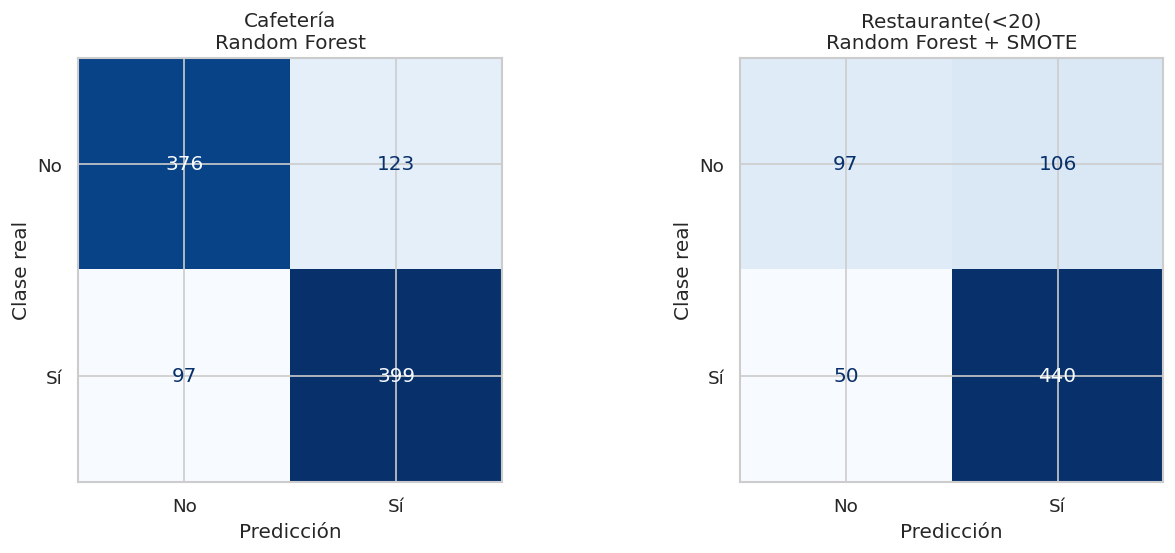


Cafetería - Random Forest
              precision    recall  f1-score   support

          No     0.7949    0.7535    0.7737       499
          Sí     0.7644    0.8044    0.7839       496

    accuracy                         0.7789       995
   macro avg     0.7796    0.7790    0.7788       995
weighted avg     0.7797    0.7789    0.7788       995


Restaurante(<20) - Random Forest + SMOTE
              precision    recall  f1-score   support

          No     0.6599    0.4778    0.5543       203
          Sí     0.8059    0.8980    0.8494       490

    accuracy                         0.7749       693
   macro avg     0.7329    0.6879    0.7019       693
weighted avg     0.7631    0.7749    0.7630       693



In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, tipo in zip(axes, tipos_cupon):
    nombre = seleccionados[tipo]
    pred = predicciones_test[(tipo, nombre)]
    ConfusionMatrixDisplay.from_predictions(
        particiones[tipo]['y_test'], pred, labels=[0, 1], display_labels=['No', 'Sí'],
        ax=ax, cmap='Blues', colorbar=False
    )
    ax.set(title=f'{tipo}\n{nombre}', xlabel='Predicción', ylabel='Clase real')
plt.show()

for tipo in tipos_cupon:
    nombre = seleccionados[tipo]
    print(f'\n{tipo} - {nombre}')
    print(classification_report(particiones[tipo]['y_test'], predicciones_test[(tipo, nombre)],
                                labels=[0, 1], target_names=['No', 'Sí'], digits=4, zero_division=0))

## 14. Variables más relevantes

Se utiliza la importancia por reducción de impureza de Random Forest para ambos tipos de cupón. Se suman las importancias de las categorías one-hot de cada variable para recuperar sus nombres originales. La tabla conserva también el detalle por categoría.

Estas importancias describen cómo el bosque utiliza las variables; no indican el sentido del efecto ni causalidad. Pueden favorecer variables con más categorías y repartir la importancia entre variables relacionadas. Las preguntas de interpretación se responderán después a partir de estas salidas.


 Cafetería - Random Forest sin balanceo


,Importancia agregada
Variable,
frecuencia_cafeteria,0.1405
ocupacion,0.1077
ingreso,0.0829
edad,0.0717
educacion,0.0546
hora,0.0536
frecuencia_bar,0.0520
frecuencia_comida_para_llevar,0.0489
frecuencia_restaurante_20_a_50,0.0467


,Característica,Variable,Importancia
84,cat__frecuencia_cafeteria_nunca,frecuencia_cafeteria,0.0671
80,cat__frecuencia_cafeteria_1 a 3,frecuencia_cafeteria,0.0244
17,cat__vigencia_cupon_2 horas,vigencia_cupon,0.0214
16,cat__vigencia_cupon_1 día,vigencia_cupon,0.0210
0,num__temperatura,temperatura,0.0198
81,cat__frecuencia_cafeteria_4 a 8,frecuencia_cafeteria,0.0185
82,cat__frecuencia_cafeteria_menos de 1,frecuencia_cafeteria,0.0183
11,cat__hora_10:00 a.m.,hora,0.0171
101,cat__tiempo_cupon_mayor_15min_Sí,tiempo_cupon_mayor_15min,0.0160
100,cat__tiempo_cupon_mayor_15min_No,tiempo_cupon_mayor_15min,0.0158


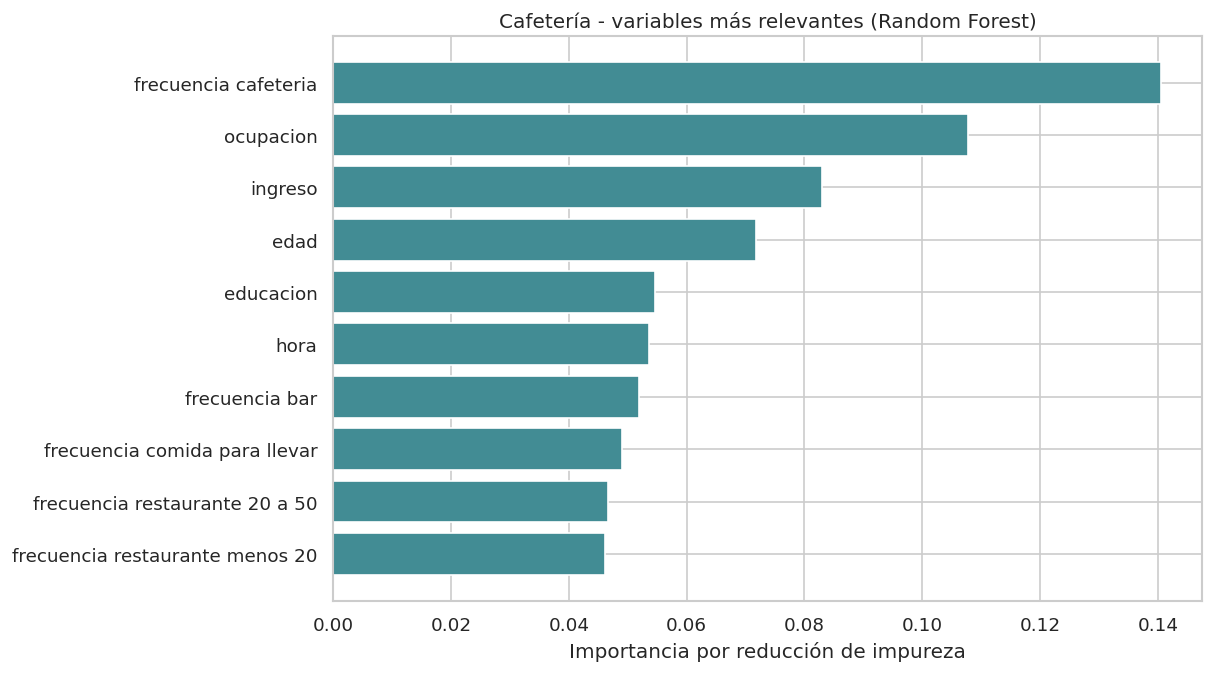


 Restaurante(<20) - Random Forest sin balanceo


,Importancia agregada
Variable,
ocupacion,0.1095
ingreso,0.0896
edad,0.0714
hora,0.0655
frecuencia_cafeteria,0.0617
educacion,0.0592
frecuencia_comida_para_llevar,0.0552
frecuencia_bar,0.0526
frecuencia_restaurante_menos_20,0.0525


,Característica,Variable,Importancia
16,cat__vigencia_cupon_1 día,vigencia_cupon,0.0243
17,cat__vigencia_cupon_2 horas,vigencia_cupon,0.0242
12,cat__hora_10:00 p.m.,hora,0.0205
14,cat__hora_6:00 p.m.,hora,0.0190
103,cat__tiempo_cupon_mayor_25min_Sí,tiempo_cupon_mayor_25min,0.0189
102,cat__tiempo_cupon_mayor_25min_No,tiempo_cupon_mayor_25min,0.0187
0,num__temperatura,temperatura,0.0186
79,cat__frecuencia_bar_nunca,frecuencia_bar,0.0166
10,cat__clima_Soleado,clima,0.0163
2,cat__destino_Sin lugar urgente,destino,0.0163


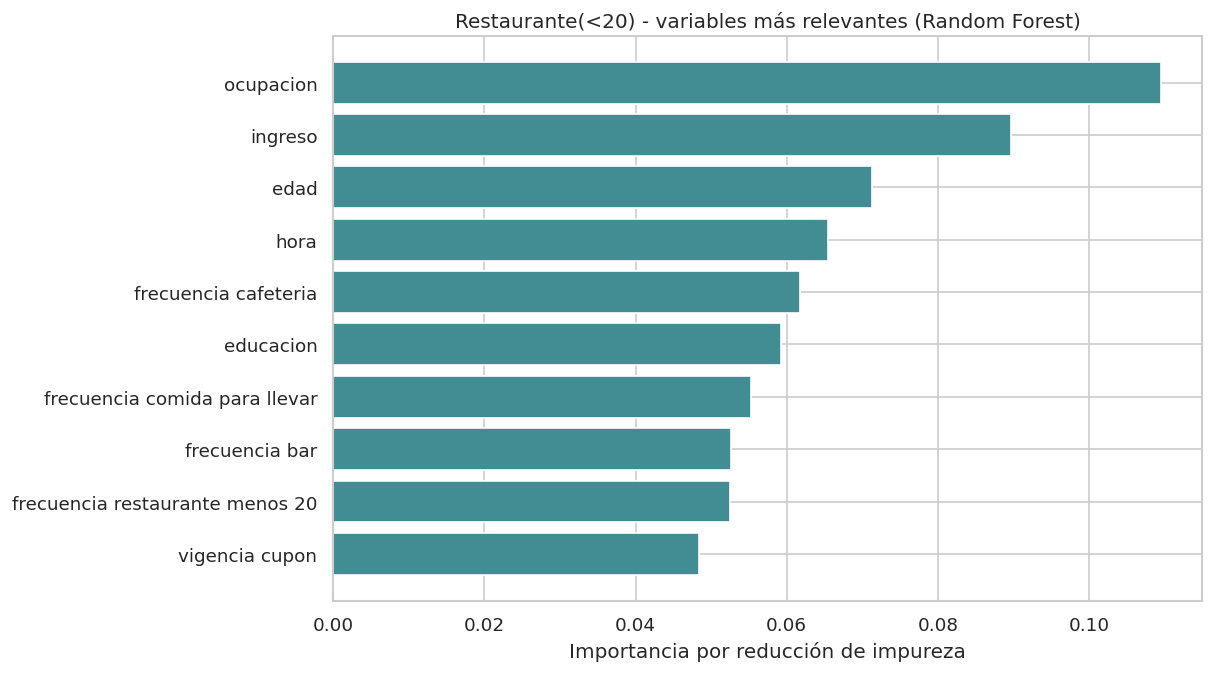

In [28]:
def obtener_importancias(grid):
    pipeline = grid.best_estimator_
    preparador = pipeline.named_steps['preprocesamiento']
    modelo = pipeline.named_steps['modelo']
    onehot = preparador.named_transformers_['cat'].named_steps['onehot']
    variables_origen = numeric_features.copy()
    for variable, categorias in zip(categorical_features, onehot.categories_):
        variables_origen.extend([variable] * len(categorias))
    detalle = pd.DataFrame({
        'Característica': preparador.get_feature_names_out(),
        'Variable': variables_origen,
        'Importancia': modelo.feature_importances_
    })
    agrupadas = detalle.groupby('Variable')['Importancia'].sum().sort_values(ascending=False)
    return detalle.sort_values('Importancia', ascending=False), agrupadas

importancias_por_cupon = {}
for tipo in tipos_cupon:
    detalle, agrupadas = obtener_importancias(busquedas[(tipo, 'Random Forest')])
    importancias_por_cupon[tipo] = agrupadas
    print('\n', tipo, '- Random Forest sin balanceo')
    display(agrupadas.rename('Importancia agregada').to_frame().round(4))
    display(detalle.head(10).round(4))
    top = agrupadas.head(10).sort_values()
    fig, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
    ax.barh(top.index.str.replace('_', ' '), top.values, color='#428c94')
    ax.set(title=f'{tipo} - variables más relevantes (Random Forest)',
           xlabel='Importancia por reducción de impureza', ylabel='')
    plt.show()

## 15. Predicciones sobre Lab3_datos_Prueba

Una vez terminada la evaluación, se clona la configuración seleccionada para cada cupón y se ajusta con todos los registros etiquetados disponibles de ese tipo. Se mantienen los hiperparámetros seleccionados; no se hace una nueva búsqueda. Las métricas anteriores corresponden a modelos entrenados sin test, antes de este ajuste final.

Se conserva el orden de las filas y las 25 columnas originales del archivo recibido. Solo se añade `acepta_cupon`, con etiquetas Sí/No. La limpieza se aplica en una copia usada para predecir, sin alterar los datos que se exportan.

In [29]:
datos_prueba_originales = pd.read_excel(ruta_datos / 'Lab3_datos_Prueba.xlsx')
datos_prueba_modelo = datos_prueba_originales.copy()
for columna in datos_prueba_modelo.select_dtypes(include='object').columns:
    datos_prueba_modelo[columna] = datos_prueba_modelo[columna].str.strip()

assert datos_prueba_modelo['cupon'].isin(tipos_cupon).all(), 'Hay tipos de cupón no modelados.'
predicciones_finales = pd.Series(index=datos_prueba_modelo.index, dtype='object')
modelos_finales = {}
for tipo in tipos_cupon:
    subconjunto = data.loc[data['cupon'] == tipo]
    X_completo = subconjunto.drop(columns=target)
    y_completo = subconjunto[target].map({'No': 0, 'Sí': 1}).astype(int)
    modelo_final = clone(busquedas[(tipo, seleccionados[tipo])].best_estimator_)
    modelo_final.fit(X_completo, y_completo)
    modelos_finales[tipo] = modelo_final
    mascara = datos_prueba_modelo['cupon'] == tipo
    pred = modelo_final.predict(datos_prueba_modelo.loc[mascara])
    predicciones_finales.loc[mascara] = np.where(pred == 1, 'Sí', 'No')
    print(f'{tipo}: {seleccionados[tipo]}, ajustado con {len(subconjunto)} registros.')

salida = datos_prueba_originales.copy()
salida[target] = predicciones_finales
assert salida[target].isin(['Sí', 'No']).all(), 'Quedaron predicciones sin asignar.'
assert salida.drop(columns=target).equals(datos_prueba_originales)
salida.to_csv('Lab3_datos_Prueba.csv', index=False, encoding='utf-8-sig')
print('Archivo generado: Lab3_datos_Prueba.csv')
print('Filas:', len(salida), '| Columnas:', len(salida.columns))
display(salida[['cupon', target]])

Cafetería: Random Forest, ajustado con 3979 registros.
Restaurante(<20): Random Forest + SMOTE, ajustado con 2769 registros.
Archivo generado: Lab3_datos_Prueba.csv
Filas: 20 | Columnas: 26


,cupon,acepta_cupon
0,Cafetería,No
1,Cafetería,Sí
2,Cafetería,Sí
3,Cafetería,Sí
4,Restaurante(<20),Sí
5,Restaurante(<20),Sí
6,Restaurante(<20),No
7,Restaurante(<20),Sí
8,Restaurante(<20),Sí
9,Cafetería,No


## 16. Análisis de resultados

Las respuestas se completarán después de revisar los resultados.

### 1. ¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?

**Respuesta:**

<!-- Pendiente de completar con los estudiantes. -->

### 2. ¿Existen variables que podrían ser redundantes o poco informativas?

**Respuesta:**

<!-- Pendiente de completar con los estudiantes. -->

### 3. ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? Si es así, ¿a qué atribuye esa diferencia?

**Respuesta:**

<!-- Pendiente de completar con los estudiantes. -->

### 4. ¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo? Justifique considerando tanto el F1-score general como el recall de la clase minoritaria.

**Respuesta:**

<!-- Pendiente de completar con los estudiantes. -->

### 5. A partir de alguno de los modelos de árbol o Random Forest describa, en términos de reglas o de importancia de variables, las características que llevan a aceptar o rechazar un cupón. Incluya la utilidad y la limitación de este tipo de interpretación.

**Respuesta:**

<!-- Pendiente de completar con los estudiantes. -->

### 6. ¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?

**Respuesta:**

<!-- Pendiente de completar con los estudiantes. -->

### 7. ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?

**Respuesta:**

<!-- Pendiente de completar con los estudiantes. -->

### 8. ¿Qué fuentes de sesgo podrían estar presentes en los datos o en el proceso de modelado, en particular al usar variables como edad, género, estado civil o nivel de ingreso para personalizar ofertas? ¿Qué implicaciones tendría este tipo de personalización si se usara para fines distintos a cupones (por ejemplo, precios dinámicos)?

**Respuesta:**

<!-- Pendiente de completar con los estudiantes. -->

## 17. Video explicativo

Máximo 3 minutos, dirigido a Ruta Alpes.

**Enlace al video:**

<!-- Pendiente. -->

## 18. Uso de herramientas de IA generativa

### Declaración del uso

Se utilizó ChatGPT para revisar el enunciado, la rúbrica, las presentaciones y el Laboratorio 2; generar una primera versión del código y las justificaciones técnicas; ejecutar las búsquedas y verificar los archivos de salida. Esta versión técnica fue generada y ejecutada con ese apoyo. La revisión por los estudiantes, las respuestas de análisis y los aportes propios están pendientes y se documentarán al completar el trabajo.

### Prompts utilizados

Prompt principal, resumido: «Revisar únicamente 202620 del repositorio, especialmente Laboratorios/L3 y su rúbrica. Desarrollar el laboratorio siguiendo la estructura y el nivel de justificación del Laboratorio 2, usando los modelos solicitados y los contenidos de las presentaciones. Ejecutar el código y dejar sin responder las preguntas y reflexiones para trabajarlas después».

### Análisis crítico del resultado

¿Qué partes del contenido generado fueron correctas y útiles?

<!-- Pendiente. -->

¿Qué errores, imprecisiones o limitaciones se identificaron?

<!-- Pendiente. -->

¿Qué decisiones técnicas fueron modificadas respecto a la respuesta de la IAG y por qué?

<!-- Pendiente. -->

¿Qué conceptos del curso permitieron evaluar o mejorar la respuesta generada?

<!-- Pendiente: responder al menos dos preguntas de este apartado. -->

### Aportes propios del estudiante

¿Qué fue desarrollado, modificado o decidido por los estudiantes? ¿Qué ajustes se realizaron y qué aprendizajes se obtuvieron?

<!-- Pendiente. -->

## 19. Materiales utilizados

- Enunciado, rúbrica y archivos de datos de `202620/Laboratorios/L3`.
- `202620/Laboratorios/L2/Laboratorio 2.ipynb`: estructura y estilo de las justificaciones.
- Prácticas P7 (regresión logística), P8 (árboles), P9 (SMOTE) y P10 (Random Forest), del periodo 202620.
- Presentaciones S3 y S4: exploración, calidad y preparación; S8: selección de modelos; S11 y S12: clasificación y métricas; S13: desbalance y ensambles; S14: ciclo de ML y evaluación.